*Note: This lab will be due after the exam, on October 14 @ midnight.*

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<img src="./src/Intraaortic_Balloon.png" width=600>

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

In [2]:
df = pd.read_csv('../data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


The point estimate of ATE was only 1% lower survival rate so I would not prefer to recieve the pump. That said there is no proof that one option is more statistically significant than the other. 

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

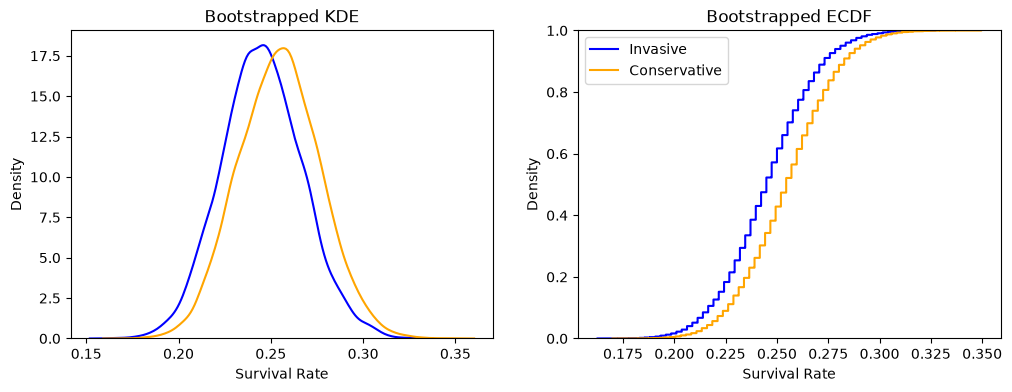

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

People who were in an invasive care situations are less likely to survive than those conservative, all else equal.

**4.** Make a plot of the KDE and ECDF for the ATE. 

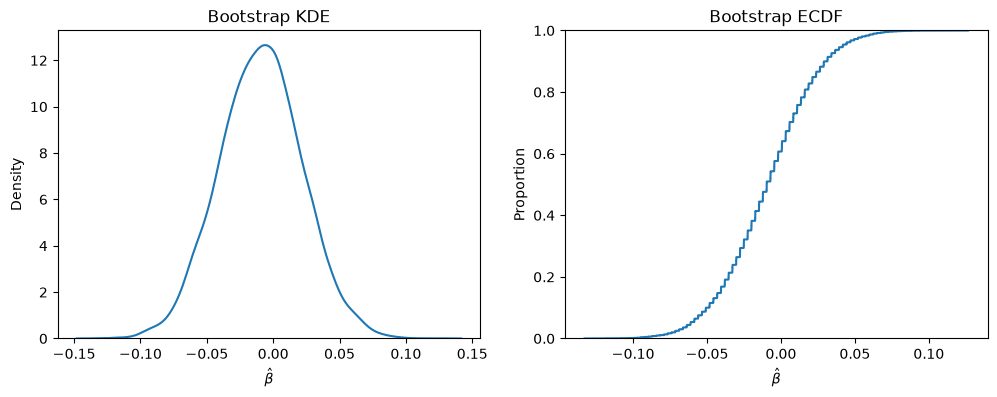

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06112057  0.04182678]
95% CI: [-0.06893187  0.05212944]
99% CI: [-0.08955586  0.07017736]


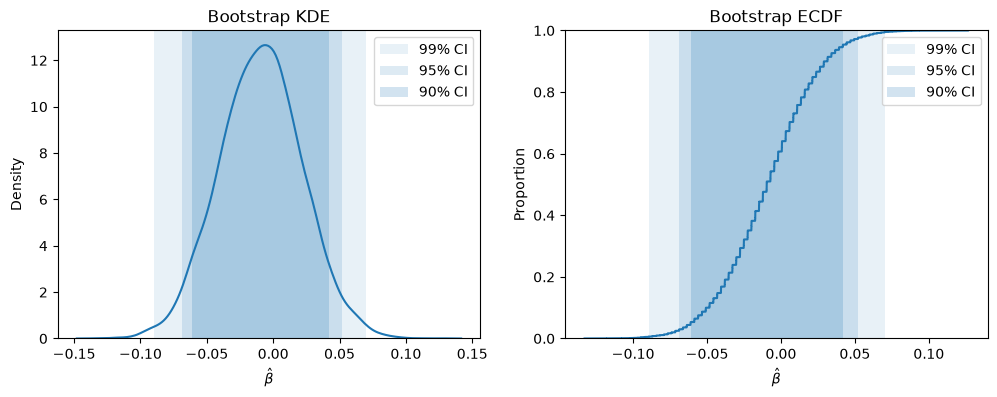

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

The distribution is fairly centered around zero, mening the baloon has no effect. Since the survival rate does not get better, doing it at all is likely not worth it. 

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

### 1.

In [8]:
diabetes = pd.read_csv('../data/diabetes.csv')
diabetes.head()

,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success


In [9]:
outcome = pd.crosstab(diabetes["treatment"], diabetes["outcome"])
print(outcome)

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143


In [10]:
diabetes["success"] = diabetes["outcome"].map({"success": 1, "failure": 0})
average_outcomes = diabetes.groupby("treatment")["success"].mean()
print(average_outcomes)

treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: success, dtype: float64


Rosiglitazone had the highest observed success rate with 61.37%, followed by lifestyle (53.41%), then metformin (48.28%). 

### 2.

In [11]:
B = 10000

met_boot = []
rosi_boot = []
lifestyle_boot = []

for i in range(B):
    met = diabetes[diabetes["treatment"] == "met"]["success"].sample(frac=1, replace=True).mean()
    rosi = diabetes[diabetes["treatment"] == "rosi"]["success"].sample(frac=1, replace=True).mean()
    lifestyle = diabetes[diabetes["treatment"] == "lifestyle"]["success"].sample(frac=1, replace=True).mean()
    
    met_boot.append(met)
    rosi_boot.append(rosi)
    lifestyle_boot.append(lifestyle)

In [12]:
boot_results = pd.DataFrame({"met": met_boot, "rosi": rosi_boot, "lifestyle": lifestyle_boot})
boot_results.head()

,met,rosi,lifestyle
0,0.508621,0.630901,0.547009
1,0.495690,0.613734,0.517094
2,0.508621,0.579399,0.534188
3,0.465517,0.532189,0.568376
4,0.482759,0.630901,0.529915


### 3.

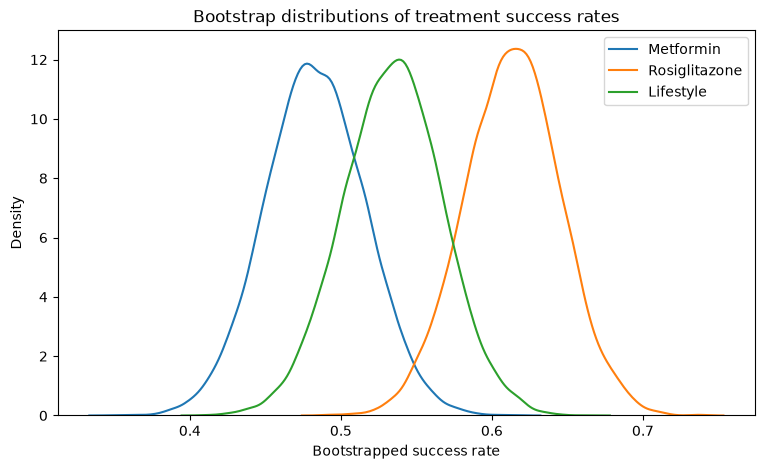

In [13]:
plt.figure(figsize=(9, 5))

sns.kdeplot(boot_results["met"], label="Metformin")
sns.kdeplot(boot_results["rosi"], label="Rosiglitazone")
sns.kdeplot(boot_results["lifestyle"], label="Lifestyle")

plt.xlabel("Bootstrapped success rate")
plt.ylabel("Density")
plt.title("Bootstrap distributions of treatment success rates")
plt.legend()
plt.show()

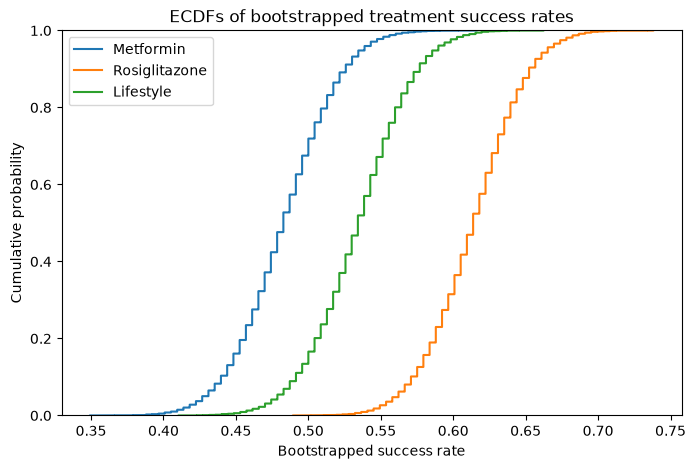

In [14]:
plt.figure(figsize=(8, 5))

sns.ecdfplot(boot_results["met"], label="Metformin")
sns.ecdfplot(boot_results["rosi"], label="Rosiglitazone")
sns.ecdfplot(boot_results["lifestyle"], label="Lifestyle")

plt.xlabel("Bootstrapped success rate")
plt.ylabel("Cumulative probability")
plt.title("ECDFs of bootstrapped treatment success rates")
plt.legend()
plt.show()

The rosiglitazone distribution is shifted furthest to the right which means it has the highest estimated success rate. The lifestyle distribution is in the middle and the metformin is shifted furthest left with the lowest success rate. The distributions overlap which shows some slight uncertainty in the treatment estimates, but on average rosiglitazone has most positive outcome.

### 4.

In [16]:
boot_results["met_vs_rosi"] = (boot_results["met"] - boot_results["rosi"])

boot_results["met_vs_lifestyle"] = (boot_results["met"] - boot_results["lifestyle"])

boot_results["rosi_vs_lifestyle"] = (boot_results["rosi"] - boot_results["lifestyle"])

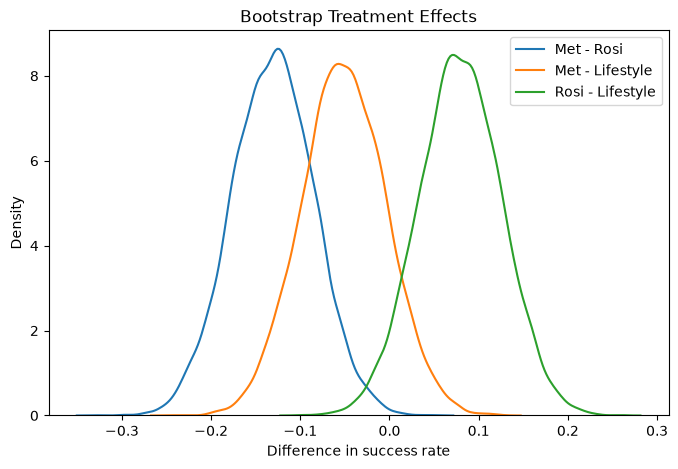

In [ ]:
plt.figure(figsize=(8, 5))

sns.kdeplot(boot_results["met_vs_rosi"], label="Met - Rosi")
sns.kdeplot(boot_results["met_vs_lifestyle"], label="Met - Lifestyle")
sns.kdeplot(boot_results["rosi_vs_lifestyle"], label="Rosi - Lifestyle")

plt.xlabel("Difference in success rate")
plt.ylabel("Density")
plt.title("Bootstrap Treatment Effects")
plt.legend()
plt.show()

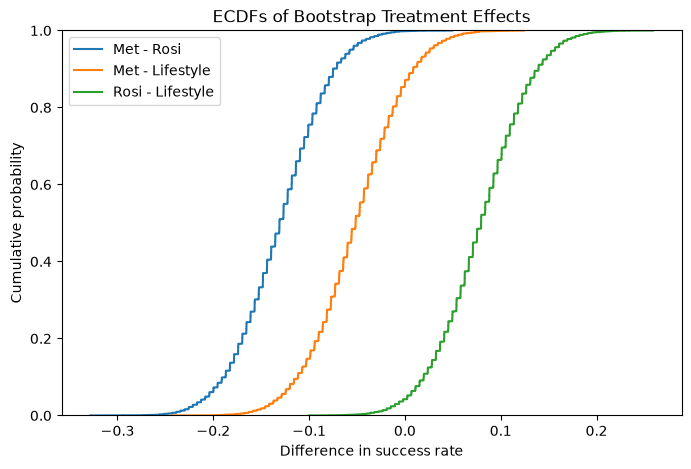

In [20]:
plt.figure(figsize=(8, 5))

sns.ecdfplot(boot_results["met_vs_rosi"], label="Met - Rosi")
sns.ecdfplot(boot_results["met_vs_lifestyle"], label="Met - Lifestyle")
sns.ecdfplot(boot_results["rosi_vs_lifestyle"], label="Rosi - Lifestyle")
plt.xlabel("Difference in success rate")
plt.ylabel("Cumulative probability")
plt.title("ECDFs of Bootstrap Treatment Effects")
plt.legend()
plt.show()

### 5.

In [22]:
print("Met vs Rosi:", np.percentile(boot_results["met_vs_rosi"], [2.5, 97.5]))

print("Met vs Lifestyle:", np.percentile(boot_results["met_vs_lifestyle"], [2.5, 97.5]))

print("Rosi vs Lifestyle:", np.percentile(boot_results["rosi_vs_lifestyle"], [2.5, 97.5]))

Met vs Rosi: [-0.22130753 -0.04071703]
Met vs Lifestyle: [-0.14183705  0.04280872]
Rosi vs Lifestyle: [-0.01049118  0.16943619]


The 95% percentile bootstrap confidence interval for metformin versus rosiglitazone was [-0.221,-0.041] which means that rosiglitazone has a higher success rate than metformin. This matches what the graph shows since those two ECDFs are not near eachother. The confidence intervals for metformin versus lifestyle [-0.142,0.043] and rosiglitazone versus lifestyle [-0.010,0.169] both include 0, so those differences are not statistically significant even though one of them barely includes zero on the lower bound. Rosiglitazone has the highest success rate and is the most effective treatment based on these tests.

Note: I used AI to help organize the variables and make the graphs cleaner, but I amd able to explain what all of my outputs are showing. 

### 6. 

I first started by assessing the success rates of each individual treatment's success rate for diabetes. The success rate results were 48.3% for metformin, 61.4% for rosiglitazone, and 53.4% for lifestyle. These seem generally close to one another, but we do not have the full picture until they are compared to one another. Based on these results, rosiglitazone had the highest success rate but by a slim margin. To get a better grasp of the significance of these margin of sucess rates, more tests had to be done. 

The next step was bootstrapping the results 10,000 times to have a better understanding of how uncertian the outcomes are. This resulted in data that significantly overlapped, but also showed that rosiglitazone's success rate was still generally higher. Since the data overlapped, I could not make any strong conclusion but it was clear that the success rates were ot equal.

I then created 95% percentile bootstrap confidence intervals for comparing the pairs of treatments. Since only one interval did not include zero, the only statistically significant finding was that rosiglitazone is more successful than metformin. The other comparisons resulted in trends that were not statistically significant enough to conclude, but it was still clear that rosiglitazone is the most successful treatment overall. With more bootstrapped trials and a potentially larger confidence interval, it is likely that the overall conclusion is rosiglitazone is truly the most successful treatemnt. 